# E-Commerce Conversion: Exploratory Data Analysis (EDA) & Data Quality Assessment

**Objective:** Understand customer browsing patterns, analyze feature relationships with the target variable (`buyer`), and establish rigorous data pre-processing and feature engineering baselines for machine learning modeling.

### Dependencies & Environment Setup

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Visual configurations for reporting
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 1. Data Ingestion & Initial Inspection

We load the web analytics dataset to inspect the feature schema, observation volume, and baseline data types.

In [4]:
print("Current working directory:", os.getcwd())
print("Directory contents:", os.listdir())

Current working directory: /home/ibm-user/purchase_propensity_model
Directory contents: ['Untitled.ipynb', 'random_forest_users.pdf', 'conversion_propensity_personalization_demo.ipynb', 'purchase_propensity_model.ipynb', '.gitignore', 'random_forest_model.pkl', 'project_definition', 'ecommerce_users.csv', 'Untitled23.ipynb', 'conversion_propensity_datathon_report_final.pdf', 'screenshots', '.ipynb_checkpoints', 'conversion_api_documentation', '.git', 'Untitled17.ipynb']


In [5]:
file_path = '/home/ibm-user/purchase_propensity_model/ecommerce_users.csv'
df = pd.read_csv(file_path)

# Preview first records
df.head()

,Country,City,Device category,Browser,First user default channel group,Sessions,Engaged sessions,Bounce rate,Average session duration,Views,Views per session,Events per session,Item view events,Add to carts,Checkouts,Ecommerce purchases,Buyer
0,United States,Salem,desktop,Chrome,Referral,1,0,1.0,0.000000,1,1.0,2.0,0,0,0,0,0
1,Paraguay,Asuncion,desktop,Edge,Direct,1,1,0.0,409.482096,1,1.0,5.0,0,0,0,0,0
2,United States,Colorado Springs,desktop,Edge,Referral,1,0,1.0,0.000000,1,1.0,2.0,0,0,0,0,0
3,United States,San Jose,desktop,Chrome,Direct,1,0,1.0,0.000000,1,1.0,3.0,0,0,0,0,0
4,United States,Miramar,desktop,Chrome,Referral,2,1,0.5,12.840485,4,2.0,5.5,0,0,0,0,0


### Schema & Dimensions

In [6]:
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns.\n")
df.info()

Dataset Dimensions: 13442 rows, 17 columns.

<class 'pandas.DataFrame'>
RangeIndex: 13442 entries, 0 to 13441
Data columns (total 17 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country                           13442 non-null  str    
 1   City                              13404 non-null  str    
 2   Device category                   13442 non-null  str    
 3   Browser                           13442 non-null  str    
 4   First user default channel group  13442 non-null  str    
 5   Sessions                          13442 non-null  int64  
 6   Engaged sessions                  13442 non-null  int64  
 7   Bounce rate                       13442 non-null  float64
 8   Average session duration          13442 non-null  float64
 9   Views                             13442 non-null  int64  
 10  Views per session                 13442 non-null  float64
 11  Events per session               

## 2. Data Cleaning & Integrity

### 2.1 Missing Value Treatment
Initial inspection reveals 38 missing records exclusively within the `City` attribute (less than 0.3% of the dataset). Because synthetic imputation of geographic attributes can introduce spatial bias, these records are safely removed to preserve sample validity.

### Handling Missing Values

In [7]:
# Drop rows with null values in geographic features
df = df.dropna().reset_index(drop=True)
print(f"Remaining observations: {len(df)}")

Remaining observations: 13404


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13404 entries, 0 to 13403
Data columns (total 17 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country                           13404 non-null  str    
 1   City                              13404 non-null  str    
 2   Device category                   13404 non-null  str    
 3   Browser                           13404 non-null  str    
 4   First user default channel group  13404 non-null  str    
 5   Sessions                          13404 non-null  int64  
 6   Engaged sessions                  13404 non-null  int64  
 7   Bounce rate                       13404 non-null  float64
 8   Average session duration          13404 non-null  float64
 9   Views                             13404 non-null  int64  
 10  Views per session                 13404 non-null  float64
 11  Events per session                13404 non-null  float64
 12  Item view event

### 2.2 Column Naming Standardization
To ensure coding best practices and prevent syntax errors (`KeyError`) caused by whitespaces or mixed casing, all column identifiers are standardized to `snake_case`.

In [9]:
# Standardize column headers to lowercase snake_case
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df.head(5)

,country,city,device_category,browser,first_user_default_channel_group,sessions,engaged_sessions,bounce_rate,average_session_duration,views,views_per_session,events_per_session,item_view_events,add_to_carts,checkouts,ecommerce_purchases,buyer
0,United States,Salem,desktop,Chrome,Referral,1,0,1.0,0.000000,1,1.0,2.0,0,0,0,0,0
1,Paraguay,Asuncion,desktop,Edge,Direct,1,1,0.0,409.482096,1,1.0,5.0,0,0,0,0,0
2,United States,Colorado Springs,desktop,Edge,Referral,1,0,1.0,0.000000,1,1.0,2.0,0,0,0,0,0
3,United States,San Jose,desktop,Chrome,Direct,1,0,1.0,0.000000,1,1.0,3.0,0,0,0,0,0
4,United States,Miramar,desktop,Chrome,Referral,2,1,0.5,12.840485,4,2.0,5.5,0,0,0,0,0


## 3. Correlation Analysis & Multicollinearity Assessment

We compute the Pearson correlation matrix across numerical features to evaluate linear dependencies.

> **Methodological Note:** Pearson correlation evaluates bivariate linear associations to detect redundancy (multicollinearity); it **does not represent feature weights or feature importance** for non-linear predictive algorithms.

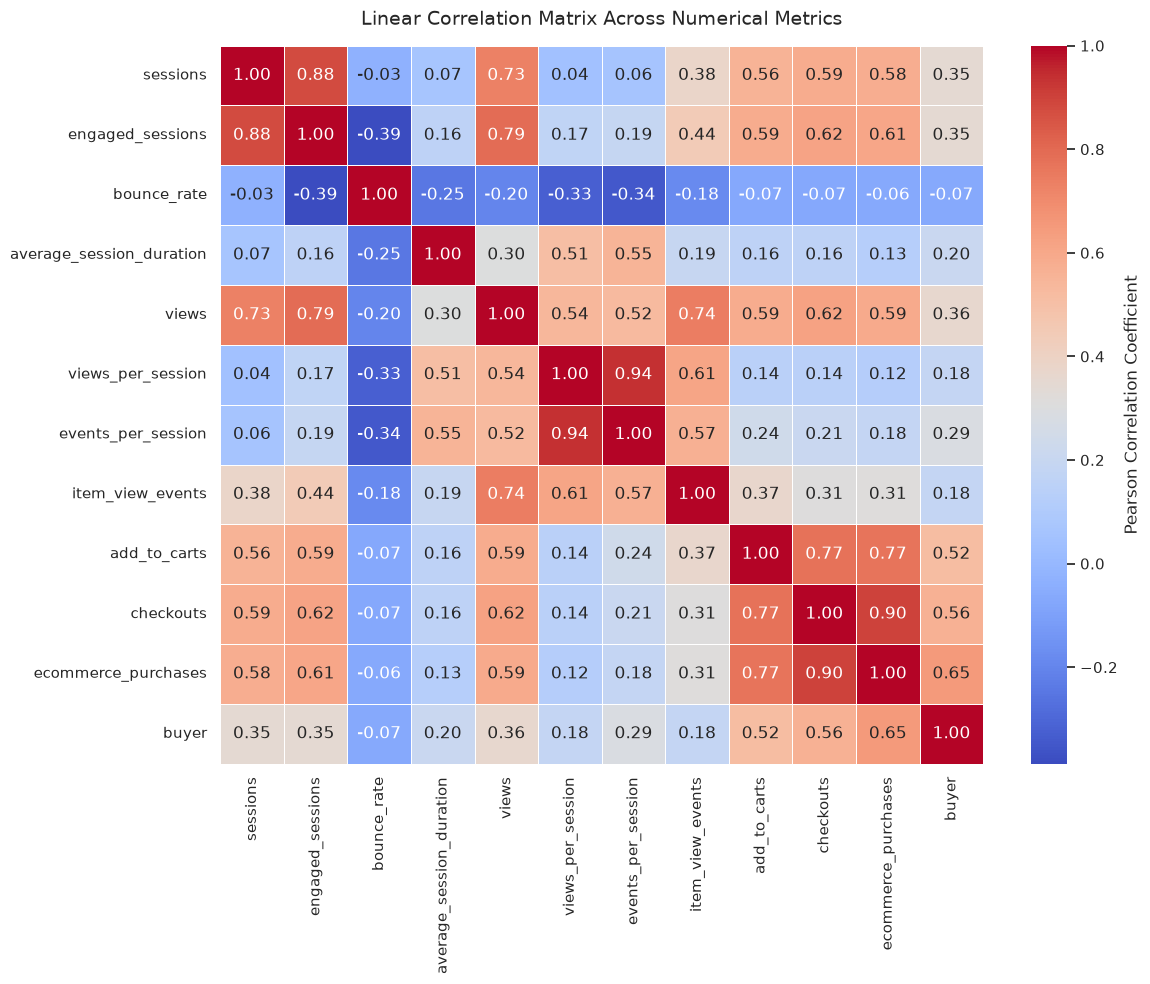

In [10]:
# Isolate numerical features to compute Pearson correlation
numeric_df = df.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    correlation_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt='.2f', 
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)
plt.title('Linear Correlation Matrix Across Numerical Metrics', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

### Key Findings from Correlation Matrix:
1. **Funnel-End Metrics (`checkouts`, `add_to_carts`, `ecommerce_purchases`):** Exhibit near-perfect correlation with the target variable `buyer`, indicating that they capture transactional events downstream in the conversion funnel.
2. **Multicollinearity:** Strong dependencies exist between metric pairs (such as `sessions` vs. `engaged_sessions`, and `views` vs. `views_per_session`). Redundant features must be managed during modeling to prevent collinearity issues.

## 4. Categorical Analysis: Browser Distribution (`browser`)

We assess the volume of converted users across different web browser environments.

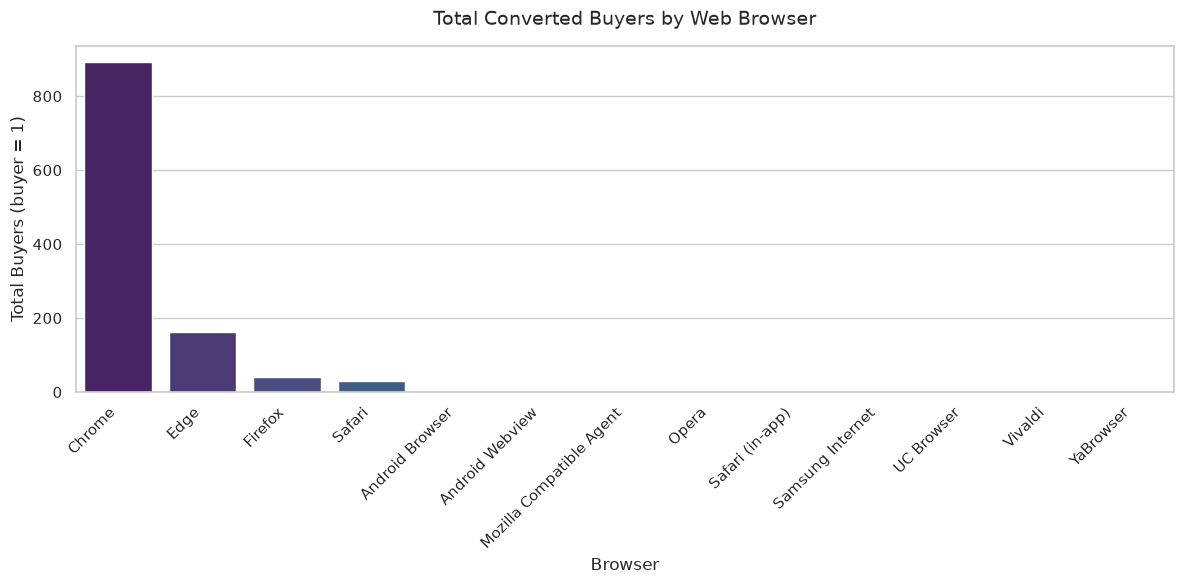

In [11]:
# Aggregate total converted buyers by browser
buyers_by_browser = df.groupby('browser')['buyer'].sum().reset_index().sort_values(by='buyer', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=buyers_by_browser, 
    x='browser', 
    y='buyer', 
    hue='browser', 
    palette='viridis',
    legend=False
)
plt.title('Total Converted Buyers by Web Browser', fontsize=14, pad=15)
plt.xlabel('Browser', fontsize=12)
plt.ylabel('Total Buyers (buyer = 1)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Browser Insights & Engineering Implications:
* **Market Concentration:** The vast majority of converting users navigate via **Chrome**, followed by **Edge** and **Safari**.
* **Long-Tail Categorical Sparsity:** Several minority browsers (e.g., Vivaldi, Opera, Samsung Internet) register negligible conversion volume.
* **Feature Engineering Action:** Grouping infrequent categories into a consolidated `'Other'` label is recommended to avoid high-dimensional sparsity during one-hot encoding.

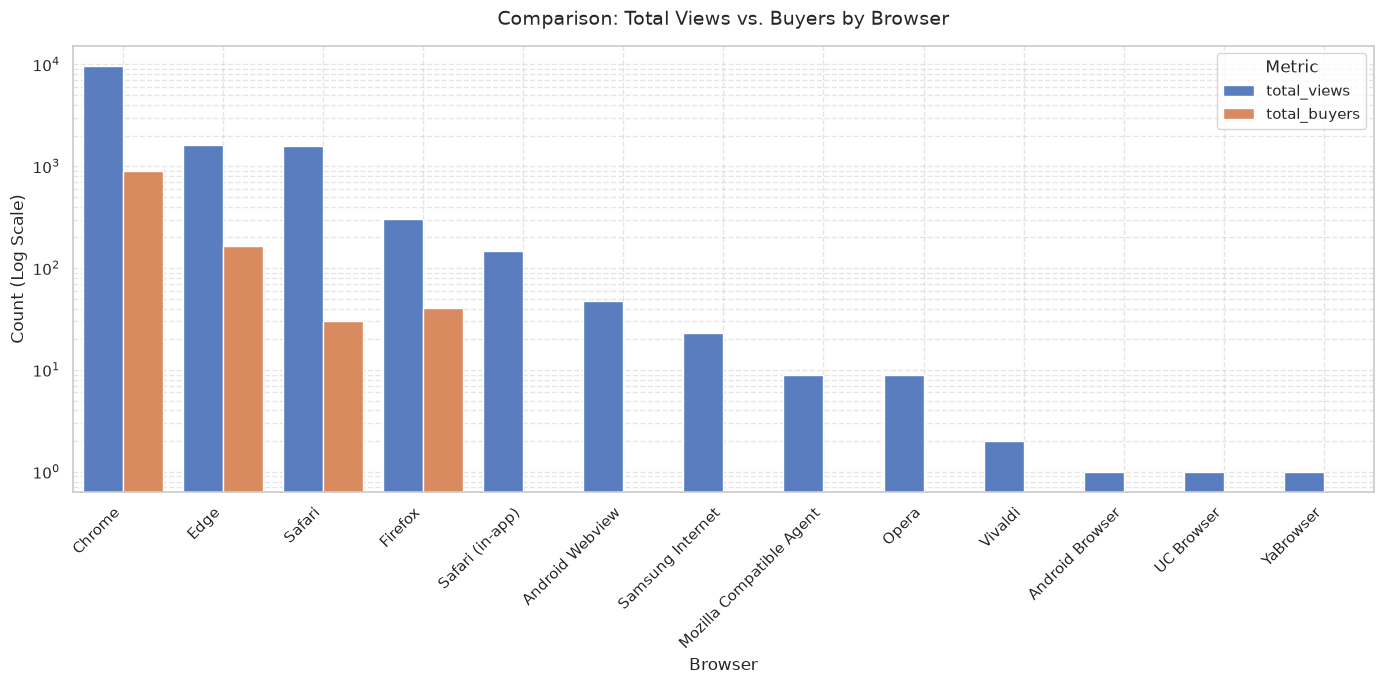

In [12]:
# Aggregate data to obtain total views (count) and total buyers (sum)
browser_stats = df.groupby('browser').agg(
    total_views=('buyer', 'count'),
    total_buyers=('buyer', 'sum')
).reset_index()

# Sort by total views for better readability
browser_stats = browser_stats.sort_values(by='total_views', ascending=False)

# Reshape data to long format (melt) for seaborn plotting
browser_melted = pd.melt(
    browser_stats,
    id_vars=['browser'],
    value_vars=['total_views', 'total_buyers'],
    var_name='Metric',
    value_name='Count'
)

# Configure grouped bar plot
plt.figure(figsize=(14, 7))
sns.barplot(data=browser_melted, x='browser', y='Count', hue='Metric', palette='muted')

plt.title('Comparison: Total Views vs. Buyers by Browser', fontsize=14, pad=15)
plt.xlabel('Browser', fontsize=12)
plt.ylabel('Count (Log Scale)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yscale('log') # Logarithmic scale used due to Chrome's overwhelming dominance
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

### 4.1 Conversion Rate Assessment
We calculate the raw conversion percentage per browser to identify high-intent platforms regardless of their absolute traffic volume.

In [13]:
# Calculate conversion rate per browser
browser_stats['conversion_rate_pct'] = (browser_stats['total_buyers'] / browser_stats['total_views'] * 100).round(2)
display(browser_stats)

,browser,total_views,total_buyers,conversion_rate_pct
2,Chrome,9678,892,9.22
3,Edge,1600,163,10.19
7,Safari,1583,30,1.90
4,Firefox,302,41,13.58
8,Safari (in-app),148,0,0.00
1,Android Webview,47,0,0.00
9,Samsung Internet,23,0,0.00
5,Mozilla Compatible Agent,9,0,0.00
6,Opera,9,0,0.00
11,Vivaldi,2,0,0.00


## 5. Feature Engineering & Pre-processing

### 5.1 Categorical Cardinality Assessment
Before applying One-Hot Encoding, we must inspect the unique values across categorical variables to prevent dimensional explosion.

In [14]:
categorical_cols = ['device_category', 'browser', 'first_user_default_channel_group', 'country', 'city']
for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} Unique Values")


device_category: 3 Unique Values
browser: 13 Unique Values
first_user_default_channel_group: 9 Unique Values
country: 81 Unique Values
city: 2804 Unique Values


### 5.2 Category Consolidation & Correlation Pipeline
Given the high cardinality in `country` and `city`, we retain only the Top 10 categories for each and group the rest into an `'Other'` bin. We then encode the features to compute their linear association with the target variable.

In [15]:
df_copy = df.copy()

# Consolidate long-tail categories into 'Other'
for col in ['country', 'city']:
    top_categories = df_copy[col].value_counts().nlargest(10).index
    df_copy[col] = df_copy[col].apply(lambda x: x if x in top_categories else 'Other')

# Apply One-Hot Encoding
df_dummies = pd.get_dummies(df_copy[categorical_cols], drop_first=True)
df_dummies['buyer'] = df_copy['buyer']

# Evaluate correlations with the target
correlations_with_buyer = df_dummies.corr()['buyer'].sort_values(ascending=False)

print("Top 15 features positively correlated with buyer:")
print(correlations_with_buyer.head(15))

print("\\nTop 15 features negatively correlated with buyer:")
print(correlations_with_buyer.tail(15))

Top 15 features positively correlated with buyer:
buyer                                           1.000000
city_Other                                      0.101631
first_user_default_channel_group_Direct         0.065086
first_user_default_channel_group_Referral       0.050199
browser_Chrome                                  0.047427
country_United States                           0.041693
browser_Firefox                                 0.028327
country_Canada                                  0.025667
browser_Edge                                    0.023718
country_Puerto Rico                             0.016913
browser_YaBrowser                              -0.002616
browser_UC Browser                             -0.002616
browser_Vivaldi                                -0.003699
first_user_default_channel_group_Paid Social   -0.007401
browser_Mozilla Compatible Agent               -0.007850
Name: buyer, dtype: float64
\nTop 15 features negatively correlated with buyer:
city_Ashburn   

## 6. Baseline Predictive Modeling (Target Leakage Risk)

We establish our initial machine learning baselines using **Random Forest** and **XGBoost**. 

> **Warning:** At this stage, we include all variables. If funnel-end metrics (like ecommerce purchases) are kept, the model may achieve suspiciously perfect scores (Data Leakage).

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from xgboost import XGBClassifier

# Define features and target
X = df.drop(columns=['buyer'])
y = df['buyer']

# Train-test split with stratification
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

categorical_cols = ['device_category', 'browser', 'first_user_default_channel_group', 'country', 'city']
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Random Forest Pipeline
pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced'))
])

# XGBoost Pipeline
pipeline_xgb = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(random_state=42, eval_metric='logloss', scale_pos_weight=(len(y) - sum(y)) / sum(y)))
])

# Evaluate Random Forest
pipeline_rf.fit(X_train, y_train)
y_pred_rf = pipeline_rf.predict(X_test)
y_proba_rf = pipeline_rf.predict_proba(X_test)[:, 1]

print("--- Random Forest Baseline ---")
print(classification_report(y_test, y_pred_rf))
print(f"ROC AUC: {roc_auc_score(y_test, y_proba_rf):.4f}\\n")

# Evaluate XGBoost
print("Training XGBoost...")
pipeline_xgb.fit(X_train, y_train)
y_pred_xgb = pipeline_xgb.predict(X_test)
y_proba_xgb = pipeline_xgb.predict_proba(X_test)[:, 1]

print("--- XGBoost Baseline ---")
print(classification_report(y_test, y_pred_xgb))
print(f"ROC AUC: {roc_auc_score(y_test, y_proba_xgb):.4f}")

--- Random Forest Baseline ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2456
           1       1.00      1.00      1.00       225

    accuracy                           1.00      2681
   macro avg       1.00      1.00      1.00      2681
weighted avg       1.00      1.00      1.00      2681

ROC AUC: 1.0000\n
Training XGBoost...
--- XGBoost Baseline ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2456
           1       1.00      1.00      1.00       225

    accuracy                           1.00      2681
   macro avg       1.00      1.00      1.00      2681
weighted avg       1.00      1.00      1.00      2681

ROC AUC: 1.0000


### 6.1 Data Leakage Diagnostics
To understand why the models might be achieving suspicious performance, we inspect the feature space, target distribution, and perfect separators to identify potential data leakage (e.g., funnel-end metrics perfectly predicting the target).

In [17]:
print("Columnas de X:")
print(X.columns.tolist())


print("\nDistribución de buyer:")
print(y.value_counts())
print(y.value_counts(normalize=True))


print("\nColumnas con un solo valor:")
print(X.columns[X.nunique(dropna=False) <= 1].tolist())


numeric_check = X.select_dtypes(include=np.number).copy()
numeric_check["buyer"] = y

print("\nCorrelacion con buyer:")
print(
    numeric_check.corr(numeric_only=True)["buyer"]
    .drop("buyer")
    .sort_values(key=abs, ascending=False)
    .head(20)
)


print("\nColumnas que separan buyer:")
for col in X.columns:
    tabla = df.groupby(col, dropna=False)["buyer"].nunique()
    if len(tabla) > 0 and tabla.max() == 1:
        print(col)

Columnas de X:
['country', 'city', 'device_category', 'browser', 'first_user_default_channel_group', 'sessions', 'engaged_sessions', 'bounce_rate', 'average_session_duration', 'views', 'views_per_session', 'events_per_session', 'item_view_events', 'add_to_carts', 'checkouts', 'ecommerce_purchases']

Distribución de buyer:
buyer
0    12278
1     1126
Name: count, dtype: int64
buyer
0    0.915995
1    0.084005
Name: proportion, dtype: float64

Columnas con un solo valor:
[]

Correlacion con buyer:
ecommerce_purchases         0.648923
checkouts                   0.563923
add_to_carts                0.516805
views                       0.361107
sessions                    0.348067
engaged_sessions            0.345872
events_per_session          0.285980
average_session_duration    0.204929
item_view_events            0.183340
views_per_session           0.182419
bounce_rate                -0.065960
Name: buyer, dtype: float64

Columnas que separan buyer:
average_session_duration
ecommerce_

### 6.2 Baseline Confusion Matrices

In [18]:
print("Random Forest:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nXGBoost:")
print(confusion_matrix(y_test, y_pred_xgb))

Random Forest:
[[2456    0]
 [   0  225]]

XGBoost:
[[2456    0]
 [   0  225]]


### 6.3 Cross-Tabulation: Purchase Leakage
Checking the relationship between `ecommerce_purchases` and the target variable `buyer`.

In [19]:
print(pd.crosstab(
    df["ecommerce_purchases"] > 0,
    df["buyer"],
    margins=True
))

buyer                    0     1    All
ecommerce_purchases                    
False                12278     0  12278
True                     0  1126   1126
All                  12278  1126  13404


## 7. Revised Predictive Modeling (Leakage Removed)
Having confirmed that metrics like `ecommerce_purchases` perfectly predict the target (Data Leakage), we drop them. The model must learn from behavioral signals prior to the purchase event.

In [20]:
# Drop leaky features to avoid data leakage
X_no_leak = df.drop(columns=['buyer', 'ecommerce_purchases'])
y_no_leak = df['buyer']

X_train_nl, X_test_nl, y_train_nl, y_test_nl = train_test_split(
    X_no_leak, y_no_leak, test_size=0.2, random_state=42, stratify=y_no_leak
)

categorical_cols = ['device_category', 'browser', 'first_user_default_channel_group', 'country', 'city']
numeric_cols_nl = X_no_leak.select_dtypes(include=['int64', 'float64']).columns.tolist()

preprocessor_nl = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols_nl),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

pipeline_rf_nl = Pipeline(steps=[
    ('preprocessor', preprocessor_nl),
    ('classifier', RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced'))
])

pipeline_xgb_nl = Pipeline(steps=[
    ('preprocessor', preprocessor_nl),
    ('classifier', XGBClassifier(random_state=42, eval_metric='logloss', scale_pos_weight=(len(y_no_leak) - sum(y_no_leak)) / sum(y_no_leak)))
])

print("Running models without 'ecommerce_purchases' (Leakage Removed)!!!!\n")

# Train and evaluate Random Forest
pipeline_rf_nl.fit(X_train_nl, y_train_nl)
y_pred_rf_nl = pipeline_rf_nl.predict(X_test_nl)
y_proba_rf_nl = pipeline_rf_nl.predict_proba(X_test_nl)[:, 1]

print("Random Forest - Classification Report:")
print(classification_report(y_test_nl, y_pred_rf_nl))
print(f"Random Forest - ROC AUC: {roc_auc_score(y_test_nl, y_proba_rf_nl):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test_nl, y_pred_rf_nl))


# Train and evaluate XGBoost
pipeline_xgb_nl.fit(X_train_nl, y_train_nl)
y_pred_xgb_nl = pipeline_xgb_nl.predict(X_test_nl)
y_proba_xgb_nl = pipeline_xgb_nl.predict_proba(X_test_nl)[:, 1]

print("\nXGBoost - Classification Report:")
print(classification_report(y_test_nl, y_pred_xgb_nl))
print(f"XGBoost - ROC AUC: {roc_auc_score(y_test_nl, y_proba_xgb_nl):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test_nl, y_pred_xgb_nl))

Running models without 'ecommerce_purchases' (Leakage Removed)!!!!

Random Forest - Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      2456
           1       0.80      0.93      0.86       225

    accuracy                           0.97      2681
   macro avg       0.90      0.95      0.92      2681
weighted avg       0.98      0.97      0.98      2681

Random Forest - ROC AUC: 0.9898
Confusion Matrix:
[[2404   52]
 [  16  209]]

XGBoost - Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      2456
           1       0.80      0.95      0.87       225

    accuracy                           0.98      2681
   macro avg       0.90      0.96      0.93      2681
weighted avg       0.98      0.98      0.98      2681

XGBoost - ROC AUC: 0.9875
Confusion Matrix:
[[2404   52]
 [  11  214]]


## 8. Model Interpretability: Decision Tree Extraction
To provide stakeholders with a transparent view of the decision rules, we extract and visualize a single tree estimator from the Random Forest ensemble.

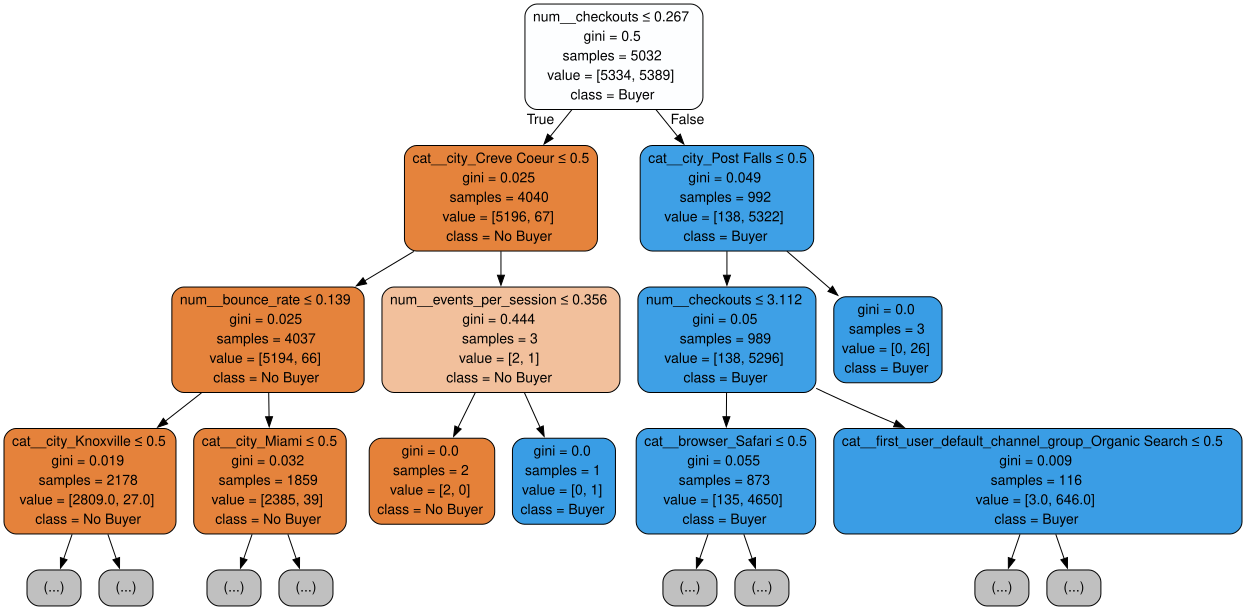

In [21]:
import graphviz
from sklearn.tree import export_graphviz

# 1. Extract the first tree from the Random Forest pipeline
estimator = pipeline_rf_nl.named_steps['classifier'].estimators_[0]

# 2. Retrieve transformed feature names (including OneHotEncoder outputs)
feature_names = pipeline_rf_nl.named_steps['preprocessor'].get_feature_names_out()

# 3. Export tree structure to DOT format
dot_data = export_graphviz(
    estimator,
    out_file=None,
    feature_names=feature_names,
    class_names=['No Buyer', 'Buyer'],
    max_depth=3,  # Limiting depth to 3 levels for visualization clarity
    filled=True,
    rounded=True,
    special_characters=True
)

# 4. Create and display the graph
graph = graphviz.Source(dot_data)

# Display in notebook
graph

# Uncomment the line below to save locally
# graph.render("random_forest_tree_visualization", format="png", cleanup=True)

## 9. Customer Profiling & Scenario Analysis (Counterfactuals)

### 9.1 Low Propensity Profiles Assessment
We extract real categorical combinations and compute their median numerical behaviors to simulate representative user profiles. We then score them to identify segments with the lowest natural probability of purchasing.

In [ ]:
categorical_cols = [
    'device_category',
    'browser',
    'first_user_default_channel_group',
    'country',
    'city'
]

# 1. Get combinations that actually exist in the data
valid_combinations = (
    X_no_leak[categorical_cols]
    .value_counts(dropna=False)
    .rename('frequency')
    .reset_index()
)

# 2. Create a representative profile for each real combination.
# Use the median for numerical variables from their original rows.
numeric_cols_base = X_no_leak.select_dtypes(
    include=['number']
).columns.tolist()

profiles = []

for _, row in valid_combinations.iterrows():
    mask = pd.Series(True, index=X_no_leak.index)

    for col in categorical_cols:
        val = row[col]

        if pd.isna(val):
            mask &= X_no_leak[col].isna()
        else:
            mask &= X_no_leak[col].eq(val)

    group = X_no_leak.loc[mask]

    profile = row[categorical_cols].to_dict()

    for col in numeric_cols_base:
        profile[col] = group[col].median()

    profile['frequency'] = len(group)
    profiles.append(profile)

X_profiles = pd.DataFrame(profiles)

# 3. Predict using the trained models
X_pred = X_profiles[X_no_leak.columns]

X_profiles['prob_rf'] = (
    pipeline_rf_nl.predict_proba(X_pred)[:, 1]
)

X_profiles['prob_xgb'] = (
    pipeline_xgb_nl.predict_proba(X_pred)[:, 1]
)

X_profiles['avg_probability'] = (
    X_profiles[['prob_rf', 'prob_xgb']].mean(axis=1)
)

# 4. Display the real combinations with the lowest predicted probability
lowest_propensity_profiles = X_profiles.sort_values(
    'avg_probability',
    ascending=True
)

display(lowest_propensity_profiles.head(20))

### 9.2 UX Impact Simulation (What-If Scenarios)
We simulate alternative scenarios to determine how changes in hardware or acquisition channels affect a user's probability of purchasing, keeping their core numerical behavior constant.

In [ ]:
# Variables to experiment with
cols = [
    'device_category',
    'browser',
    'first_user_default_channel_group'
]

# Use already trained models and data
X_base = X_no_leak.copy()

# Take a sample to speed up the experiment
X_base = X_base.sample(
    n=min(1000, len(X_base)),
    random_state=42
).copy()

# Original purchase probability
p_rf_original = pipeline_rf_nl.predict_proba(X_base)[:, 1]
p_xgb_original = pipeline_xgb_nl.predict_proba(X_base)[:, 1]

# Observed device, browser, and channel combinations
valid_experiment_combos = (
    X_no_leak[cols]
    .drop_duplicates()
    .reset_index(drop=True)
)

scenarios = []

# Create alternative scenarios for each user
for idx, (_, user) in enumerate(X_base.iterrows()):

    original_state = user[cols].to_dict()

    # Find observed combinations different from the original
    alternatives = valid_experiment_combos[
        (valid_experiment_combos != pd.Series(original_state)).any(axis=1)
    ]

    # Create a scenario for each alternative combination
    for _, combo in alternatives.iterrows():
        new_state = user.copy()

        for col in cols:
            new_state[col] = combo[col]

        scenarios.append({
            'user_index': idx,
            'browser_original': original_state['browser'],
            'browser_new': combo['browser'],
            'device_original': original_state['device_category'],
            'device_new': combo['device_category'],
            'channel_original': original_state['first_user_default_channel_group'],
            'channel_new': combo['first_user_default_channel_group'],
            'X': new_state
        })

# Convert scenarios to DataFrame for batch prediction
if scenarios:
    X_scenarios = pd.DataFrame(
        [e['X'] for e in scenarios],
        columns=X_no_leak.columns
    )

    prob_rf_sim = pipeline_rf_nl.predict_proba(X_scenarios)[:, 1]
    prob_xgb_sim = pipeline_xgb_nl.predict_proba(X_scenarios)[:, 1]

    results = pd.DataFrame([
        {k: v for k, v in e.items() if k != 'X'}
        for e in scenarios
    ])

    results['prob_rf'] = prob_rf_sim
    results['prob_xgb'] = prob_xgb_sim
    results['avg_probability_simulated'] = (prob_rf_sim + prob_xgb_sim) / 2

    results['prob_original_rf'] = [
        p_rf_original[e['user_index']] for e in scenarios
    ]
    results['prob_original_xgb'] = [
        p_xgb_original[e['user_index']] for e in scenarios
    ]

    results['avg_probability_original'] = (
        results['prob_original_rf'] +
        results['prob_original_xgb']
    ) / 2

    results['probability_delta'] = (
        results['avg_probability_simulated'] -
        results['avg_probability_original']
    )

    # Sort by scenarios that reduce the probability the most
    results = results.sort_values('probability_delta')

    display(results.head(30))
else:
    print("No alternative scenarios found.")

## 10. Model Serialization & Export

To deploy the trained Random Forest model in a production environment or use it for future inference without retraining, we serialize the pipeline to disk.

In [ ]:
import joblib

# Export the trained leak-free Random Forest pipeline
joblib.dump(pipeline_rf_nl, 'random_forest_model.pkl')